## Text and Sequence — Advanced Machine Learning

### Preparation

In [1]:
# ---------------------------------------------------------------------
# Setup
# ---------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import imdb
from tensorflow.keras.utils import pad_sequences

EPOCHS = 10
BATCH_SIZE = 32
MAX_WORDS = 150          # cut every review at 150 words
NUM_WORDS = 10000        # top 10,000 words only
VAL_SAMPLES = 10000      # validate on 10,000 samples


### 1. Load the IMDB data

Reviews are already integer-encoded word IDs. Training is restricted to 100 samples; validation is the first 10,000 of the test split. Every review is cut or padded to exactly 150 words.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = imdb.load_data(num_words=NUM_WORDS)

x_val = pad_sequences(x_test[:VAL_SAMPLES], maxlen=MAX_WORDS)
y_val = y_test[:VAL_SAMPLES]

print('Full training set:', x_train_full.shape)
print('Validation set:   ', x_val.shape)
print('First review, first 20 word IDs:', x_train_full[0][:20])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Full training set: (25000,)
Validation set:    (10000, 150)
First review, first 20 word IDs: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]


### 2. Train one model and report its best validation accuracy

Both models use the same training procedure, only the embedding changes:
RMSprop, binary crossentropy, accuracy. Best validation accuracy = the highest validation accuracy over the epochs.

In [3]:
def train_and_report(label, model, x_train, y_train):
    model.compile(optimizer='rmsprop',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    model.summary()
    history = model.fit(x_train, y_train,
                        epochs=EPOCHS, batch_size=BATCH_SIZE,
                        validation_data=(x_val, y_val), verbose=2)
    best = max(history.history['val_accuracy'])
    best_epoch = int(np.argmax(history.history['val_accuracy'])) + 1
    print(f'{label} -- best validation accuracy: {best:.4f} (epoch {best_epoch})')
    return history, best, best_epoch


def plot_curves(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training accuracy')
    plt.plot(epochs, val_acc, label='Validation accuracy')
    plt.title(title + ' — accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training loss')
    plt.plot(epochs, val_loss, label='Validation loss')
    plt.title(title + ' — loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    plt.show()

### 3. Model A — Learned embedding (training = 100)

Training samples: (100, 150)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
4/4 - 2s - 551ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5150 - val_loss: 0.6928
Epoch 2/10
4/4 - 1s - 350ms/step - accuracy: 0.9600 - loss: 0.6410 - val_accuracy: 0.5153 - val_loss: 0.6924
Epoch 3/10
4/4 - 1s - 302ms/step - accuracy: 0.9700 - loss: 0.6080 - val_accuracy: 0.5124 - val_loss: 0.6929
Epoch 4/10
4/4 - 1s - 181ms/step - accuracy: 1.0000 - loss: 0.5772 - val_accuracy: 0.5151 - val_loss: 0.6925
Epoch 5/10
4/4 - 1s - 180ms/step - accuracy: 0.9900 - loss: 0.5472 - val_accuracy: 0.5165 - val_loss: 0.6925
Epoch 6/10
4/4 - 1s - 176ms/step - accuracy: 1.0000 - loss: 0.5181 - val_accuracy: 0.5175 - val_loss: 0.6928
Epoch 7/10
4/4 - 1s - 177ms/step - accuracy: 1.0000 - loss: 0.4886 - val_accuracy: 0.5189 - val_loss: 0.6930
Epoch 8/10
4/4 - 1s - 174ms/step - accuracy: 1.0000 - loss: 0.4571 - val_accuracy: 0.5186 - val_loss: 0.6928
Epoch 9/10
4/4 - 1s - 173ms/step - accuracy: 1.0000 - loss: 0.4264 - val_accuracy: 0.5187 - val_loss: 0.6933
Epoch 10/10
4/4 - 1

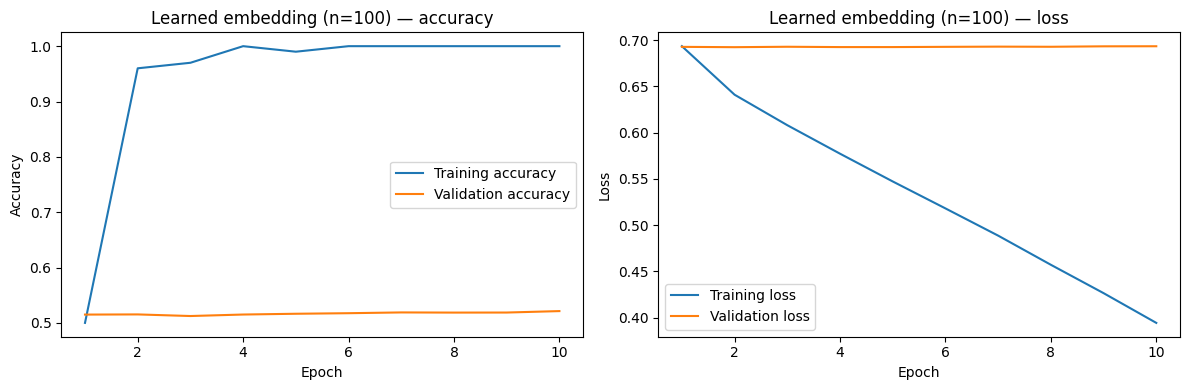

In [4]:
n = 100
x_train = pad_sequences(x_train_full[:n], maxlen=MAX_WORDS)
y_train = y_train_full[:n]
print('Training samples:', x_train.shape)

learned_model = keras.Sequential([
    layers.Embedding(NUM_WORDS, 32, input_length=MAX_WORDS),
    layers.Flatten(),
    layers.Dense(1, activation='sigmoid')
])

learned_history, learned_best, learned_epoch = train_and_report(
    'Learned embedding (n=100)', learned_model, x_train, y_train)
plot_curves(learned_history, 'Learned embedding (n=100)')

### 4. Model B — Pretrained embedding (training = 100)

Step 1 — get the GloVe file.

Step 2 — build the embedding matrix: one row per vocabulary word, filled with that word's 100-number GloVe vector (words missing from GloVe stay zeros).

Step 3 — the model: the same head as Model A. Only the embedding changes, and it is frozen (`trainable=False`) — the borrowed meanings are used as-is.

In [5]:
import os

!wget -q https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
!unzip -q -o glove.6B.zip glove.6B.100d.txt

print('GloVe file present:', os.path.exists('glove.6B.100d.txt'))


GloVe file present: True


In [6]:
embeddings_index = {}
with open('glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs
print('Words in GloVe file:', len(embeddings_index))

word_index = imdb.get_word_index()
embedding_dim = 100
embedding_matrix = np.zeros((NUM_WORDS, embedding_dim))
for word, i in word_index.items():
    if i < NUM_WORDS:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector
print('Embedding matrix:', embedding_matrix.shape)
print('Words with a GloVe vector:', int(np.count_nonzero(np.any(embedding_matrix != 0, axis=1))))

Words in GloVe file: 400000
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Embedding matrix: (10000, 100)
Words with a GloVe vector: 9796


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
4/4 - 3s - 654ms/step - accuracy: 0.5100 - loss: 1.7277 - val_accuracy: 0.5055 - val_loss: 1.0094
Epoch 2/10
4/4 - 1s - 180ms/step - accuracy: 0.6600 - loss: 0.5625 - val_accuracy: 0.5050 - val_loss: 1.1073
Epoch 3/10
4/4 - 1s - 175ms/step - accuracy: 0.9000 - loss: 0.2887 - val_accuracy: 0.5052 - val_loss: 1.1238
Epoch 4/10
4/4 - 1s - 175ms/step - accuracy: 0.9600 - loss: 0.1738 - val_accuracy: 0.5114 - val_loss: 0.9144
Epoch 5/10
4/4 - 1s - 175ms/step - accuracy: 0.9900 - loss: 0.1354 - val_accuracy: 0.5065 - val_loss: 0.7909
Epoch 6/10
4/4 - 1s - 173ms/step - accuracy: 1.0000 - loss: 0.0915 - val_accuracy: 0.5153 - val_loss: 0.8486
Epoch 7/10
4/4 - 1s - 334ms/step - accuracy: 1.0000 - loss: 0.0737 - val_accuracy: 0.5061 - val_loss: 0.7868
Epoch 8/10
4/4 - 1s - 174ms/step - accuracy: 1.0000 - loss: 0.0599 - val_accuracy: 0.5166 - val_loss: 0.8823
Epoch 9/10
4/4 - 1s - 180ms/step - accuracy: 1.0000 - loss: 0.0753 - val_accuracy: 0.5085 - val_loss: 1.1550
Epoch 10/10
4/4 - 1

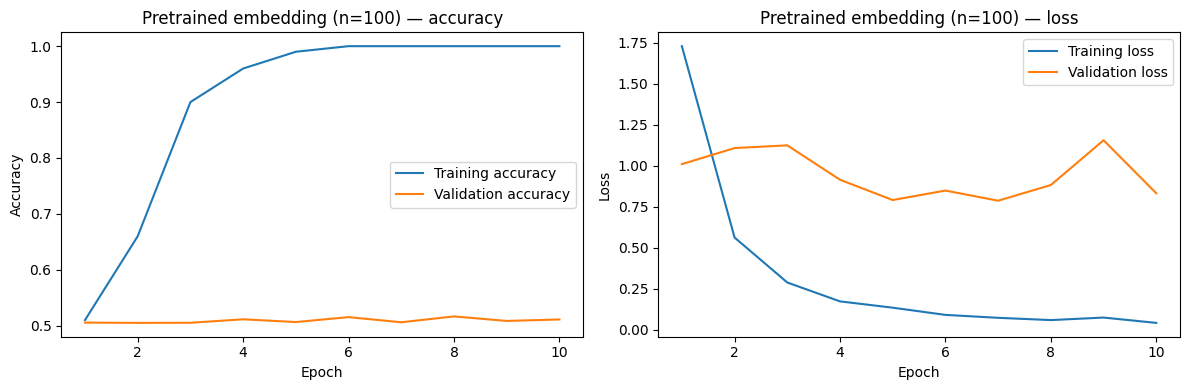

Learned (n=100):    0.5213
Pretrained (n=100): 0.5166


In [7]:
pretrained_model = keras.Sequential([
    layers.Embedding(NUM_WORDS, embedding_dim,
                      embeddings_initializer=keras.initializers.Constant(embedding_matrix),
                      trainable=False, input_length=MAX_WORDS),
    layers.Flatten(),
    layers.Dense(1, activation='sigmoid')
])

pretrained_history, pretrained_best, pretrained_epoch = train_and_report(
    'Pretrained embedding (n=100)', pretrained_model, x_train, y_train)
plot_curves(pretrained_history, 'Pretrained embedding (n=100)')

print(f'Learned (n=100):    {learned_best:.4f}')
print(f'Pretrained (n=100): {pretrained_best:.4f}')

### 5. Vary the training-sample count - change the training size and re-run both models

Only the training size changes; validation stays at 10,000 throughout, so every number compares fairly.

In [8]:
SWEEP_SIZES = [100, 500, 1000, 2500, 5000, 10000, 25000]

results = []
for n in SWEEP_SIZES:
    x_tr = pad_sequences(x_train_full[:n], maxlen=MAX_WORDS)
    y_tr = y_train_full[:n]
    print(f'\n=== Training size {n} ===')

    m_learned = keras.Sequential([
        layers.Embedding(NUM_WORDS, 32, input_length=MAX_WORDS),
        layers.Flatten(),
        layers.Dense(1, activation='sigmoid')
    ])
    _, learned_acc, _ = train_and_report(f'Learned (n={n})', m_learned, x_tr, y_tr)

    m_pre = keras.Sequential([
        layers.Embedding(NUM_WORDS, embedding_dim,
                          embeddings_initializer=keras.initializers.Constant(embedding_matrix),
                          trainable=False, input_length=MAX_WORDS),
        layers.Flatten(),
        layers.Dense(1, activation='sigmoid')
    ])
    _, pretrained_acc, _ = train_and_report(f'Pretrained (n={n})', m_pre, x_tr, y_tr)

    results.append({'n': n, 'learned': learned_acc, 'pretrained': pretrained_acc})
    print(f'n={n}: learned {learned_acc:.4f} | pretrained {pretrained_acc:.4f}')


=== Training size 100 ===


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

... (75 outputs left out)

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
782/782 - 4s - 5ms/step - accuracy: 0.5261 - loss: 0.9488 - val_accuracy: 0.5502 - val_loss: 0.8514
Epoch 2/10
782/782 - 3s - 4ms/step - accuracy: 0.6026 - loss: 0.8179 - val_accuracy: 0.5657 - val_loss: 0.8448
Epoch 3/10
782/782 - 4s - 5ms/step - accuracy: 0.6413 - loss: 0.7476 - val_accuracy: 0.5590 - val_loss: 0.9795
Epoch 4/10
782/782 - 3s - 3ms/step - accuracy: 0.6662 - loss: 0.7092 - val_accuracy: 0.5508 - val_loss: 1.0825
Epoch 5/10
782/782 - 3s - 3ms/step - accuracy: 0.6896 - loss: 0.6691 - val_accuracy: 0.5225 - val_loss: 1.5341
Epoch 6/10
782/782 - 3s - 3ms/step - accuracy: 0.7045 - loss: 0.6388 - val_accuracy: 0.5444 - val_loss: 1.2822
Epoch 7/10
782/782 - 4s - 5ms/step - accuracy: 0.7160 - loss: 0.6171 - val_accuracy: 0.5569 - val_loss: 1.1936
Epoch 8/10
782/782 - 3s - 4ms/step - accuracy: 0.7258 - loss: 0.5996 - val_accuracy: 0.5753 - val_loss: 1.0716
Epoch 9/10
782/782 - 3s - 3ms/step - accuracy: 0.7401 - loss: 0.5779 - val_accuracy: 0.5640 - val_loss: 1.2077
E

### 6. Summary — the results table and the summary graph

Training size | Learned | Pretrained
          100 | 0.5165 | 0.5145
          500 | 0.5867 | 0.5176
         1000 | 0.6731 | 0.5281
         2500 | 0.8003 | 0.5334
         5000 | 0.8346 | 0.5457
        10000 | 0.8534 | 0.5602
        25000 | 0.8662 | 0.5753


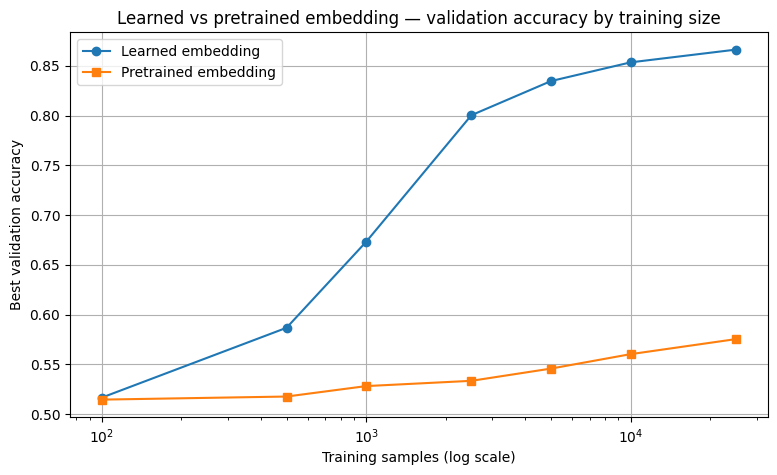

Point where learned starts beating pretrained (first n where learned > pretrained): 100


In [9]:
print('Training size | Learned | Pretrained')
for r in results:
    print(f"{r['n']:>13} | {r['learned']:.4f} | {r['pretrained']:.4f}")

sizes = [r['n'] for r in results]
learned_accs = [r['learned'] for r in results]
pretrained_accs = [r['pretrained'] for r in results]

plt.figure(figsize=(9, 5))
plt.plot(sizes, learned_accs, marker='o', label='Learned embedding')
plt.plot(sizes, pretrained_accs, marker='s', label='Pretrained embedding')
plt.xscale('log')
plt.xlabel('Training samples (log scale)')
plt.ylabel('Best validation accuracy')
plt.title('Learned vs pretrained embedding — validation accuracy by training size')
plt.legend()
plt.grid(True)
plt.show()

# Point where learned starts beating pretrained: first training size
beating_point = None
for r in results:
    if r['learned'] > r['pretrained']:
        beating_point = r['n']
        break
print('Point where learned starts beating pretrained (first n where learned > pretrained):', beating_point)
